In [1]:
import bioframe as bf
import pandas as pd
import cooler
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mp
import HMMC
import numpy as np
import os


mp.rcParams['font.size'] = 10
saveFigs = True 
if saveFigs == True:
    figure_path = '../figs/figure2S/'
    os.makedirs(figure_path, exist_ok=True)
    # to save inkscape-friendly svgs
    new_rc_params = {'text.usetex': False,
                     "svg.fonttype": 'none'}
    mp.rcParams.update(new_rc_params)

In [2]:
hmm_track = pd.read_csv('../annotations/GM12878_hg38_25kb.tsv', sep = '\t')

In [3]:
chrom_hmm_dir = '/gladstone/engelhardt/lab/lchumpitaz/datasets/chromhmm'
gm_chrom =  chrom_hmm_dir+'/E116_15_coreMarks_hg38lift_mnemonics.bed.gz'
gm_chrom_df = pd.read_csv(gm_chrom, sep='\t', header=None,
        names=['chrom', 'start', 'end', 'name'], usecols=[0, 1, 2, 3])

In [4]:
cooler_file = '/gladstone/engelhardt/lab/lchumpitaz/hi-c/mcools/4DNFIXP4QG5B.mcool'
resolution = 25000
hic_cooler = cooler.Cooler(cooler_file+'::resolutions/'+str(resolution))

In [5]:
region = 'chr9:85,731,459-93,165,754'
# region = 'chr1:13,958,846-41,444,480'
annotation_type = 'HMM3P'
chrom_state = '14_ReprPCWk'

In [6]:
chromhmm_region = bf.select(gm_chrom_df, region).copy()
genome_region = bf.select(hmm_track, region).copy()
genome_region.drop(columns=hmm_track.columns[3:], inplace=True)

chromhmm_region['signal']=0
chromhmm_region.loc[chromhmm_region.name==chrom_state, 'signal']=1

In [7]:
def bedtools_intersect_basePairs(left, right, rsuffix='_'):
    """Interval intersection with bp overlap (bioframe.overlap replaces bedtools CLI)."""
    out = bf.overlap(left, right, return_overlap=True, suffixes=('', rsuffix), how='left', keep_order=True)
    out['bpOverlap'] = out['overlap_end'] - out['overlap_start']
    return out.drop(columns=['overlap_end', 'overlap_start'])


In [8]:
inter = bedtools_intersect_basePairs(genome_region, chromhmm_region[chromhmm_region.signal==1])

In [9]:
genome_region['overlap'] = inter.groupby(by=['chrom','start']).sum().bpOverlap.values

In [10]:
height, width = 9, 7

/tmp/ipykernel_1780894/1577493272.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.yaxis.set_ticklabels(ticklabels)
/tmp/ipykernel_1780894/1577493272.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.xaxis.set_ticklabels(ticklabels)


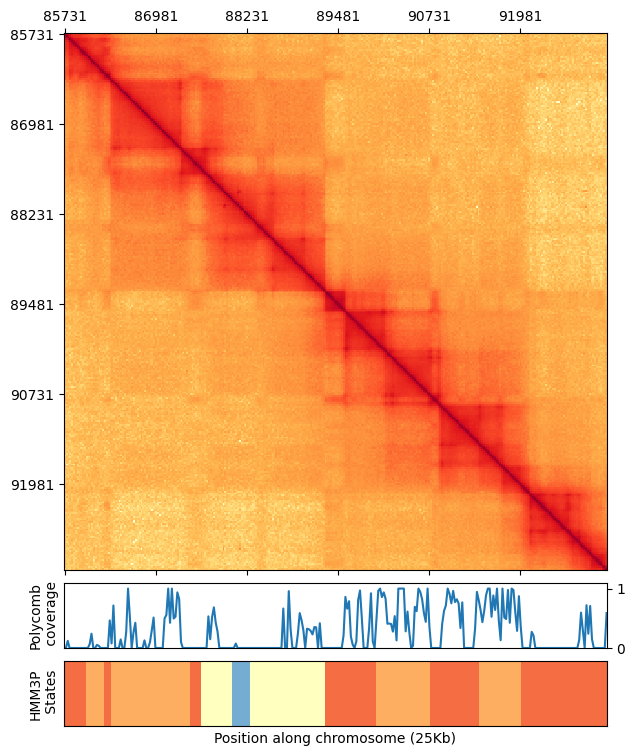

In [11]:
fig= plt.figure(1, figsize = (width, height))
gs = gridspec.GridSpec(height, width, figure=fig, wspace=2, hspace=0.2)

ax0= plt.subplot(gs[:7, :])
mat = hic_cooler.matrix(balance=True).fetch(region, region)
res = hic_cooler.binsize
im = ax0.matshow(np.log10(mat + 5e-6),cmap = 'YlOrRd', aspect='auto', interpolation ='none')

chrm, start, end = bf.parse_region(region)

ax0.yaxis.set_ticks_position('left')
ticklabels = ((ax0.yaxis.get_ticklocs()*res/1e3)+(start)/1e3).astype(int)
ax0.yaxis.set_ticklabels(ticklabels)
ax0.xaxis.set_ticklabels(ticklabels)





ax1= plt.subplot(gs[7:8, :])
ax1.plot(genome_region.start, genome_region.overlap/res)
ax1.margins(0)

ax1.set_ylabel('Polycomb\n coverage',rotation=90)
ax1.get_xaxis().set_visible(False)
ax1.yaxis.tick_right()
ax1.set_ylim([0, 1.1])





ax2= plt.subplot(gs[8:9, :])
mat_c = HMMC.track_to_mat(hmm_track, region, annotation_type, HMMC.pallete, horizontal=True)
ax2.matshow(mat_c,cmap=mp.colors.ListedColormap(HMMC.cmap), vmin=0, vmax=5, aspect='auto')

ax2.set_ylabel('HMM3P\n States',rotation=90)
ax2.yaxis.tick_right()
ax2.get_yaxis().set_ticks([])


ax2.set_xlabel('Position along chromosome (25Kb)')
ax2.get_xaxis().set_ticks([]);

# if saveFigs:
#     plt.savefig(figure_path+'hicseg_'+region.replace(',','')+'_'
#                 +annotation_type+'.svg',
#                 bbox_inches="tight")